# Local sensitivity analysis of the macrophage–T cell network

This notebook runs the forward (local) sensitivity analysis of the network with
`sensitivity.py`. It is the project version of `sensitivityanalysis.ipynb`.

* The equations are **not copied** here. The symbolic Jacobian is built from
  `NetworkEquations.interaction_terms`, the same code the simulator integrates.
* The analysis is **extended to several parameters at once**. The original
  notebook handled one (IFNGE).
* The **microenvironment cases** of the thesis (Figures 5.15–5.20) can still be
  run in Section 7.

The same engine runs from the Gradio interface (*Local sensitivity analysis*
tab). The derivation is in `docs/sensitivity_analysis.md`.

## 1. The model

The network has $n = 155$ nodes $q_i(t) \in [0,1]$ driven by $m = 43$ external
inputs $\mathbf p$ (cytokines, antigens, nutrients, drugs, interaction times,
and the saturation rate $b = p_0$):

$$
\frac{dq_i}{dt} = \varphi\big(w_i(t,\mathbf q,\mathbf p);\,b,u_i\big) - \delta_i\,q_i,
\qquad i = 1,\dots,n .
$$

Each $w_i$ is the probabilistic translation of a Boolean rule:

$$
A \wedge B \;\mapsto\; AB, \qquad
A \vee B \;\mapsto\; A + B - AB, \qquad
\neg A \;\mapsto\; 1 - A .
$$

The default activation is the sigmoid with threshold $u_i$:

$$
\varphi(w) = \frac{1}{1+e^{-b\,(w-u)}}, \qquad
\varphi'(w) = b\,\varphi(1-\varphi), \qquad
\frac{\partial\varphi}{\partial b} = (w-u)\,\varphi(1-\varphi).
$$

TCR and CD28 signalling also depend on time through the interaction windows
$1/(1+e^{\,t-T})$, with $T \in \{T_{\mathrm{MHC2}}, T_{\mathrm{CD80/86}}\}$.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from Equations import NetworkEquations
from plotting import Plotter
from subnetworks import SUBNETWORKS
from sensitivity import (SensitivityAnalyzer, MICROENVIRONMENT_CASES,
                         notebook_initial_conditions, sweep_values)

%matplotlib inline

# --- settings -------------------------------------------------------------
USE_NOTEBOOK_INITIAL_CONDITIONS = True   # reproduce sensitivityanalysis.ipynb exactly
SAVE_FIGURES = True                      # write PNGs to OUTPUT_DIR
OUTPUT_DIR = './figures'
T_SPAN = (0.0, 50.0)
SOLVER = dict(t_span=T_SPAN, n_points=500, rtol=1e-9, atol=1e-12, method='LSODA')
# --------------------------------------------------------------------------

network = NetworkEquations()
analyzer = SensitivityAnalyzer(network)
plotter = Plotter(SUBNETWORKS)

Q0 = notebook_initial_conditions(network.n) if USE_NOTEBOOK_INITIAL_CONDITIONS \
     else network.initial_conditions
SOLVER['q0'] = Q0

t0 = time.time()
analyzer.build_jacobian()
print(f"Symbolic Jacobian built in {time.time() - t0:.2f} s")

Symbolic Jacobian built in 0.86 s


## 2. Forward sensitivity equations

Define the sensitivity matrix

$$
S_{ij}(t) = \frac{\partial q_i(t)}{\partial p_j}, \qquad S \in \mathbb{R}^{n\times k},
$$

for the $k$ parameters of interest. Differentiate the ODE with respect to
$p_j$ and swap $\partial_t$ and $\partial_{p_j}$ (allowed because the
right-hand side is smooth). This gives a **linear, time-varying** ODE that is
integrated together with $\mathbf q$:

$$
\boxed{\;
\dot S = \underbrace{\big(D_\varphi\,J_{wq} - \operatorname{diag}(\boldsymbol\delta)\big)}_{A(t)}\,S
\;+\; \underbrace{D_\varphi\,J_{wp}\big|_{\text{selected}} + \Big[\frac{\partial\boldsymbol\varphi}{\partial b}\Big]_{\,j=b}}_{B(t)},
\qquad S(0) = 0 \;}
$$

where

$$
D_\varphi = \operatorname{diag}\!\big(\varphi'(w_1),\dots,\varphi'(w_n)\big), \qquad
J_{wq} = \frac{\partial\mathbf w}{\partial\mathbf q}\in\mathbb R^{n\times n}, \qquad
J_{wp} = \frac{\partial\mathbf w}{\partial\mathbf p}\in\mathbb R^{n\times m}.
$$

* $S(0)=0$ because the initial state does not depend on the inputs.
* The term $\partial\varphi/\partial b$ only appears in the column of the
  saturation rate $b$, which enters $\varphi$ directly and not through $\mathbf w$.
* The original notebook used $A = D_\varphi J_{wq} - I$, which is the special
  case $\delta_i = 1$. Here the decay rates are free.

$J_{wq}$ and $J_{wp}$ are computed **symbolically** with sympy, then turned
into numerical functions (`lambdify`) once. Only the structurally non-zero
entries are kept:

In [2]:
nnz = len(analyzer._jac_rows)
total = network.n * (network.n + analyzer.m)
print(f"Non-zero entries of dw/d[q|p]: {nnz} of {total} ({100 * nnz / total:.2f} %)")

# Example: what does the TBET term depend on?
i_tbet = analyzer.node_names.index('TBET')
names = analyzer.node_names + analyzer.input_names
deps = [names[c] for r, c in zip(analyzer._jac_rows, analyzer._jac_cols) if r == i_tbet]
print("w_TBET depends on:", ", ".join(deps))

Non-zero entries of dw/d[q|p]: 395 of 30690 (1.29 %)
w_TBET depends on: IL12OUT, IL18OUT, IL33OUT, AP1, IL2E, NFAT, NFKB, GATA3, IL4, IL10, MTORC1, AKG, IFNGE, IFNGL, IL12E, IL18E, IL33E, TRP


## 3. The augmented system

$q$ and all $k$ columns of $S$ are integrated in one call, using the state

$$
\mathbf y = \big[\;\mathbf q \;\big|\; \operatorname{vec}(S)\;\big] \in \mathbb R^{\,n(1+k)},
\qquad
\dot{\mathbf y} = \begin{pmatrix} \boldsymbol\varphi(\mathbf w) - \boldsymbol\delta\odot\mathbf q \\[2pt]
\operatorname{vec}\!\big(A(t)\,S + B(t)\big)\end{pmatrix}.
$$

All columns share the same $A(t)$, so each extra parameter costs only $n$
more states. The solver is `solve_ivp` (LSODA, $\mathrm{rtol}=10^{-9}$,
$\mathrm{atol}=10^{-12}$).

Below is a single run at the nominal inputs of case 5.15 (LPS + IFN-γ):

In [3]:
p_nominal = analyzer.case_inputs({'LPSE': 1.0, 'IFNGE': 1.0})

t0 = time.time()
nominal = analyzer.run(p_nominal, ['IFNGE'], **SOLVER)
print(f"One augmented integration ({network.n * 2} states): {time.time() - t0:.2f} s")
pd.DataFrame(analyzer.summary(nominal, ['TBET', 'IFNG'])).round(4)

One augmented integration (310 states): 0.73 s


,node,parameter,activity_min,activity_max,sensitivity_min,sensitivity_max,elasticity_min,elasticity_max,elasticity_final
0,TBET,IFNGE,0.0,0.8924,0.0,0.9896,0.0,2.0315,0.6580
1,IFNG,IFNGE,0.0,0.9376,0.0,1.3855,0.0,3.4930,0.2756


## 4. Elasticity coefficients

Raw sensitivities depend on the units of $p_j$ and on the size of $q_i$, so
the figures use normalised (logarithmic) sensitivities:

$$
\varepsilon_{ij}(t) \;=\; \frac{\partial \ln q_i}{\partial \ln p_j}
\;=\; S_{ij}(t)\,\frac{p_j}{\lvert q_i(t)\rvert}
\qquad\texttt{(relative\_pointwise)},
$$

$$
\varepsilon^{(f)}_{ij}(t) = S_{ij}(t)\,\frac{p_j}{\lvert q_i(T)\rvert}
\quad\texttt{(relative\_final)},
\qquad
\tilde S_{ij}(t) = S_{ij}(t)\,p_j
\quad\texttt{(scaled)}.
$$

$\varepsilon_{ij} = 0.5$ means that a 1 % increase of $p_j$ raises $q_i$ by
about 0.5 %. $\lvert q\rvert$ is clipped at $10^{-12}$. If $p_j = 0$ the
normalised forms vanish; use `raw` instead.

## 5. Validation against finite differences

The exact sensitivity is compared with the central difference

$$
S_{ij}(t) \approx \frac{q_i(t;\,p_j+\Delta) - q_i(t;\,p_j-\Delta)}{2\Delta},
\qquad
\big|\text{error}\big| \lesssim C_3\,\Delta^{2} + \frac{\varepsilon_{\mathrm{tol}}}{\Delta}.
$$

The truncation error ($\propto \Delta^2$) shrinks with $\Delta$. The solver
round-off ($\propto 1/\Delta$) grows. The best $\Delta$ is around
$10^{-3}$. We also check that the $q$ part of the augmented system matches
a plain integration of the network ($\max\lvert q^{\mathrm{aug}} - q^{\mathrm{base}}\rvert$).

dTBET/dIFNGE  max|exact - FD| {'1e-02': '1.6e-04', '1e-03': '1.6e-06', '1e-04': '2.1e-05'}   max|q_aug - q_base| = 5.7e-10
dTBET/dLPSE   max|exact - FD| {'1e-02': '7.7e-05', '1e-03': '6.8e-07', '1e-04': '5.9e-06'}   max|q_aug - q_base| = 1.3e-09
dTBET/db      max|exact - FD| {'1e-02': '5.1e-06', '1e-03': '5.7e-07', '1e-04': '6.7e-06'}   max|q_aug - q_base| = 1.6e-09


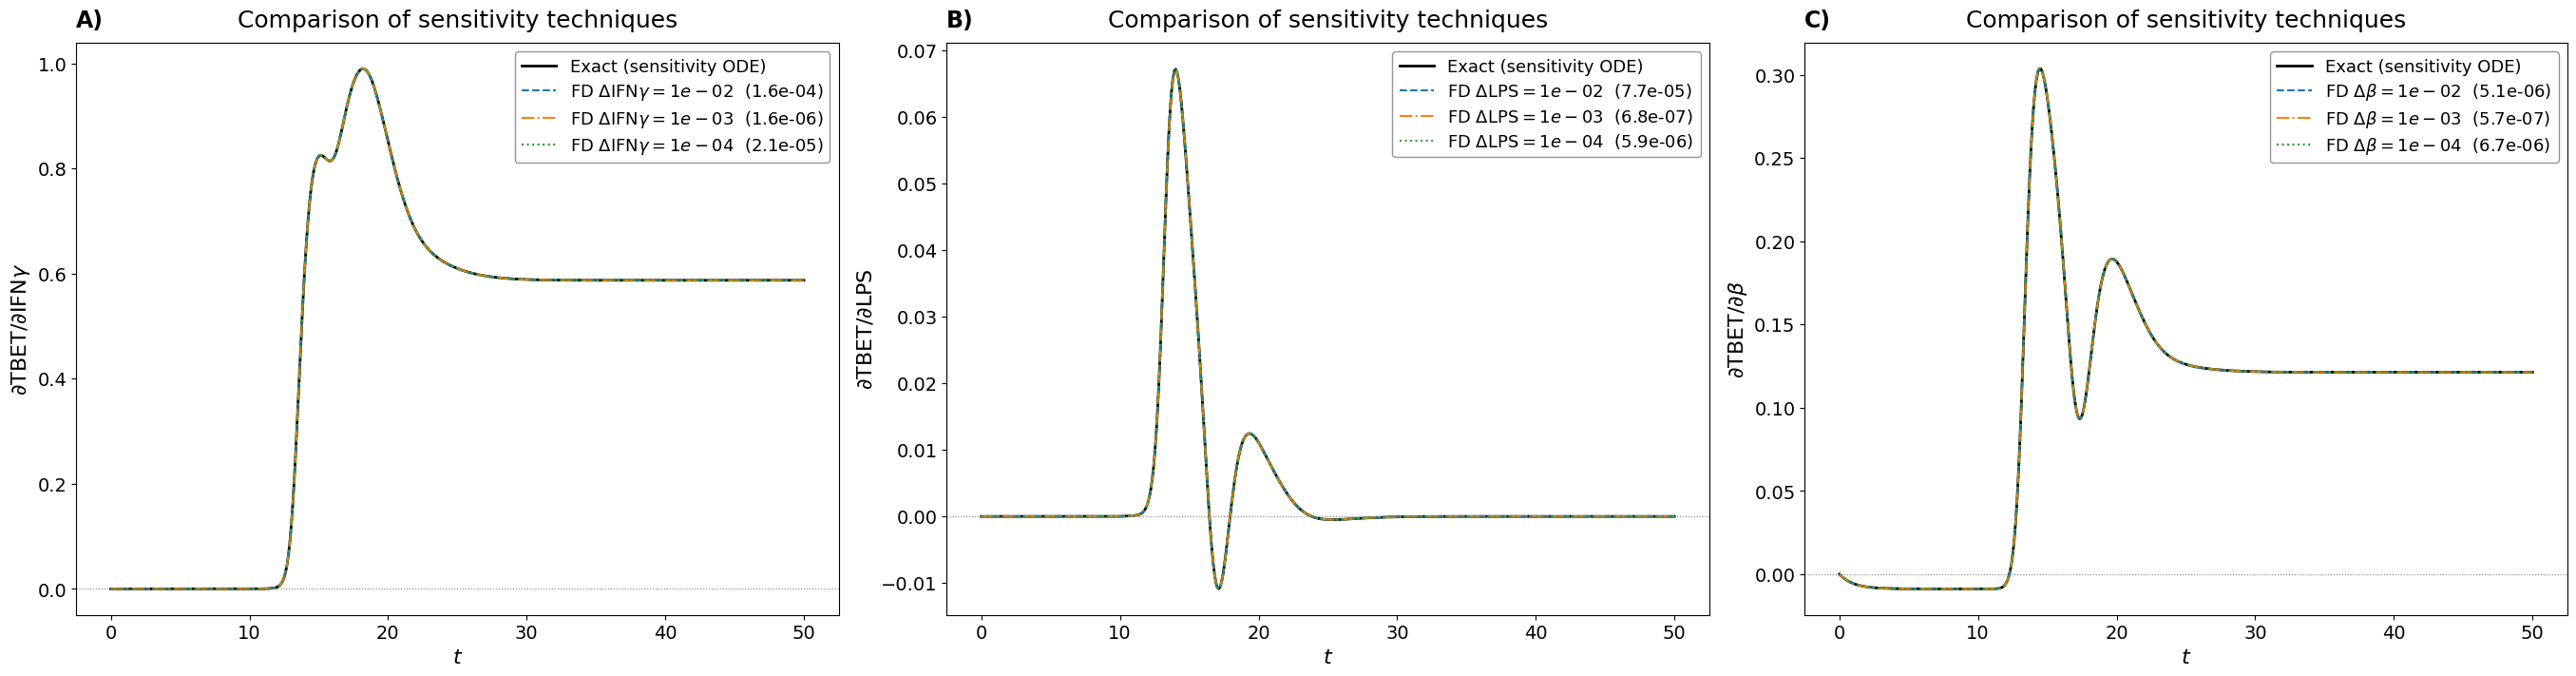

In [4]:
checks = [analyzer.finite_difference_check(p_nominal, param, 'TBET',
                                          deltas=(1e-2, 1e-3, 1e-4), **SOLVER)
          for param in ['IFNGE', 'LPSE', 'b']]
for c in checks:
    errs = {f"{d:.0e}": f"{np.max(np.abs(fd - c['exact'])):.1e}" for d, fd in c['fd'].items()}
    print(f"dTBET/d{c['param']:6s} max|exact - FD| {errs}   "
          f"max|q_aug - q_base| = {c['augmented_vs_base']:.1e}")
fig = plotter.plot_sensitivity_fd_check(checks)

## 6. Several parameters at once

With $k$ parameters, column $j$ of $S$ follows
$\dot{\mathbf S}_{\cdot j} = A(t)\,\mathbf S_{\cdot j} + \mathbf B_{\cdot j}(t)$,
and all columns are integrated together. To add a parameter, add its name to
`PARAMETERS` below; to add an output node, add it to `NODES`. The figure has
one row per node, with the node's activity first and then one elasticity
panel per parameter:

$$
\text{row } i:\quad q_i(t) \;\Big|\; \varepsilon_{i,1}(t) \;\Big|\; \cdots \;\Big|\; \varepsilon_{i,k}(t).
$$

3 runs x 620 states: 7.8 s


,node,parameter,activity_min,activity_max,sensitivity_min,sensitivity_max,elasticity_min,elasticity_max,elasticity_final
0,TBET,IFNGE,0.0,0.9385,0.0000,1.5232,0.0000,2.0682,0.4150
1,TBET,IL4L,0.0,0.9385,-0.0755,0.0000,-0.1105,0.0000,-0.0002
2,TBET,b,0.0,0.9385,-0.0088,0.3215,-3.9281,9.7374,0.7115
3,GATA3,IFNGE,0.0,0.0535,-0.4287,0.0000,-7.4873,0.0000,-0.1701
4,GATA3,IL4L,0.0,0.0535,0.0000,0.0822,0.0000,1.5515,0.0216
5,GATA3,b,0.0,0.0535,-0.0730,0.0000,-13.2794,0.0000,-4.2752


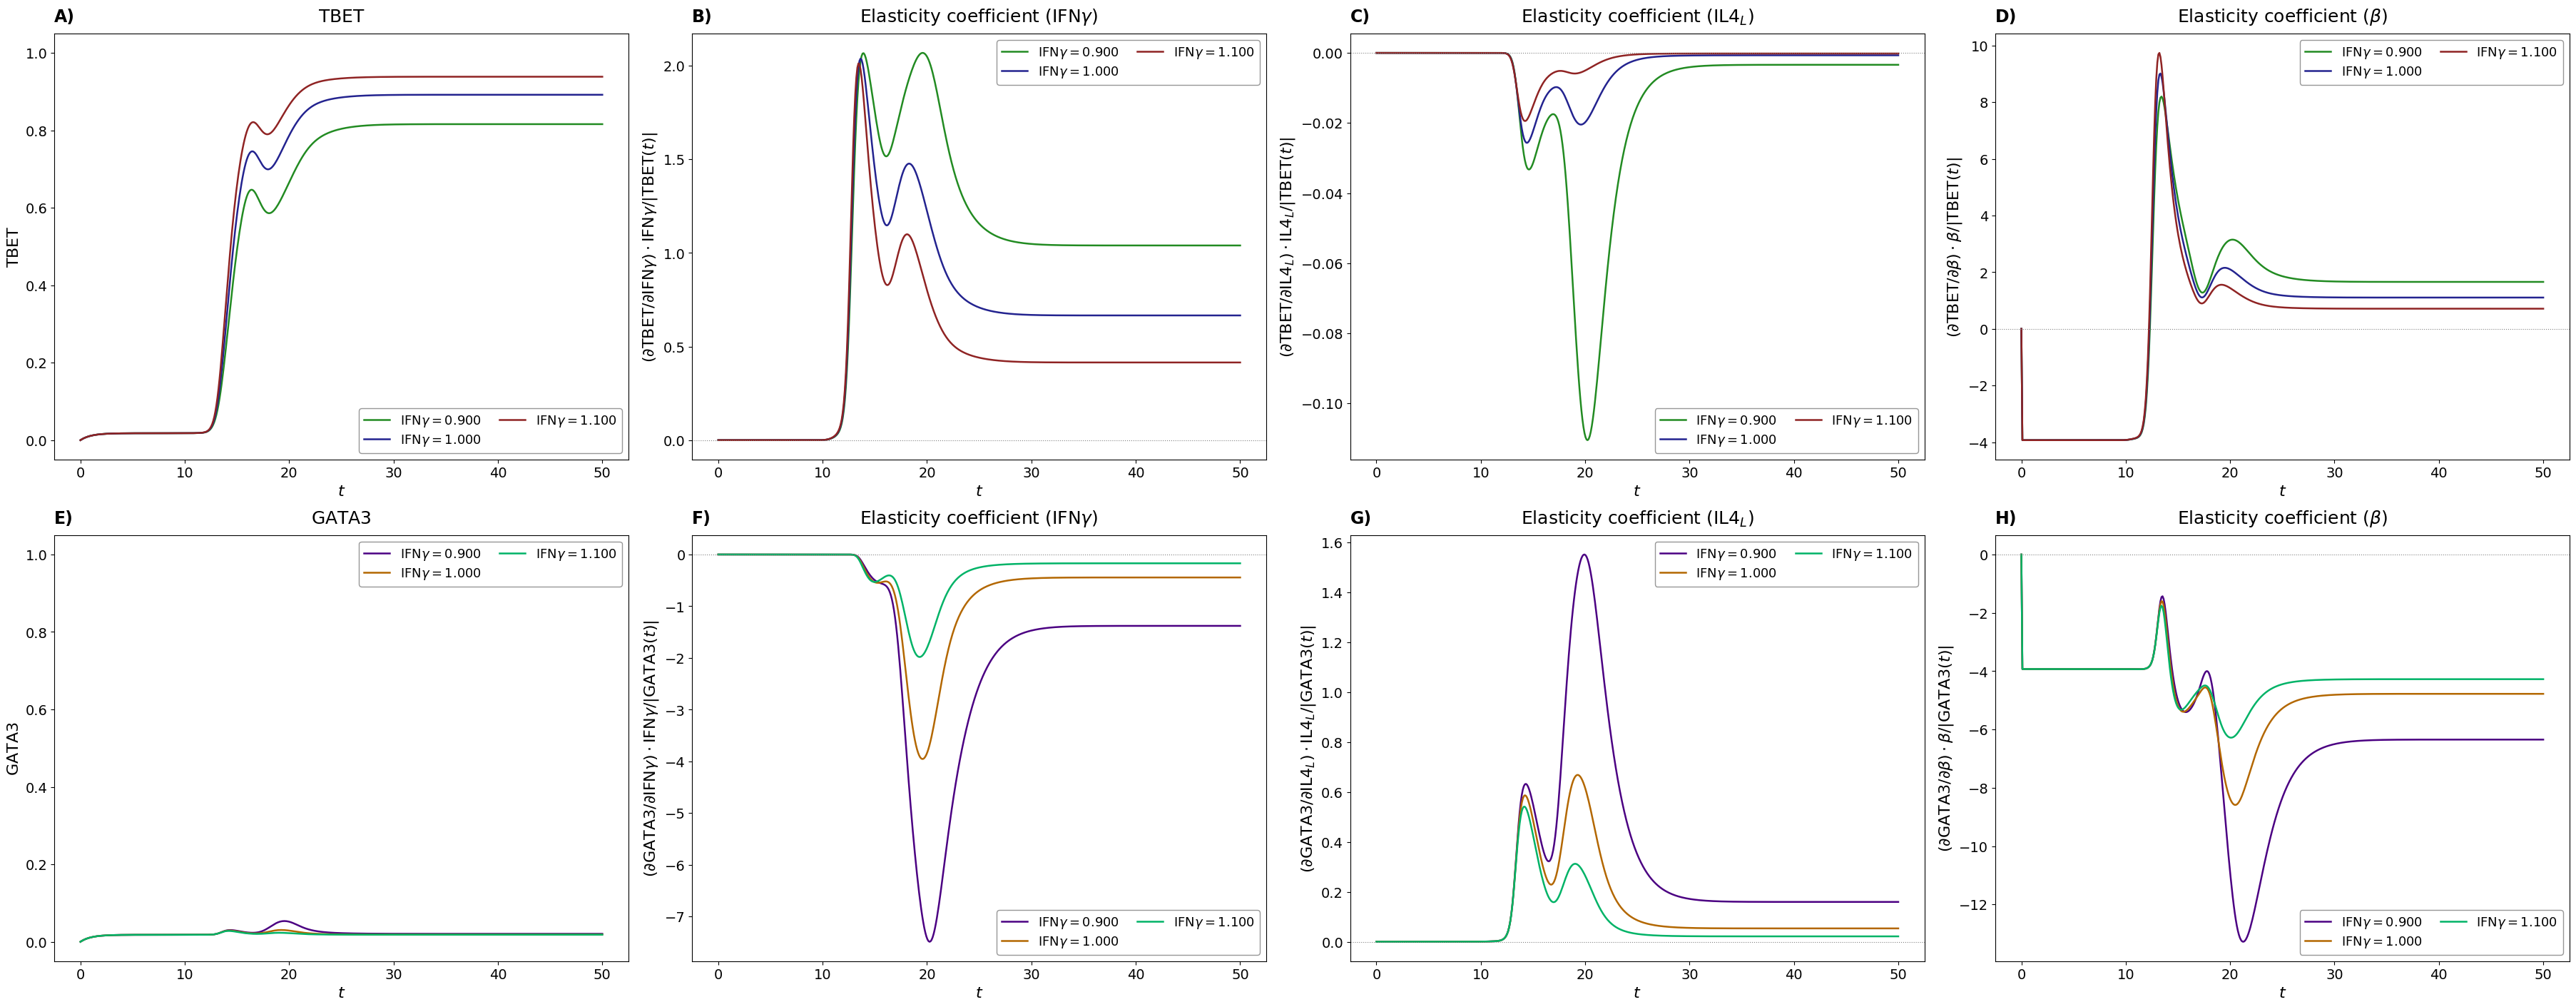

In [5]:
PARAMETERS = ['IFNGE', 'IL4L', 'b']      # any of network.out_of_network_arguments
NODES = ['TBET', 'GATA3']
SWEEP = ('IFNGE', 0.9, 1.1, 0.1)          # (parameter, start, stop, step) or None

p_multi = analyzer.case_inputs({'LPSE': 1.0, 'SSRNA': 1.0, 'IL4L': 1.0})
sweep_param, values = (SWEEP[0], sweep_values(*SWEEP[1:])) if SWEEP else (None, None)

t0 = time.time()
multi = analyzer.run(p_multi, PARAMETERS, sweep_param, values, **SOLVER)
print(f"{len(multi.sweep_values)} runs x {network.n * (1 + len(PARAMETERS))} states: "
      f"{time.time() - t0:.1f} s")
fig = plotter.plot_sensitivity_grid(multi, NODES, mode='relative_pointwise')
pd.DataFrame(analyzer.summary(multi, NODES)).round(4)

## 7. Microenvironment cases (thesis figures 5.15 – 5.20)

Each case starts from the default inputs, applies
`CASE_BASE_INPUTS` $=\{\mathrm{LPS}=1,\ \mathrm{IFN}\gamma=1\}$ and then its own
microenvironment. It then sweeps
$p_{\mathrm{IFN}\gamma} \in \{p_{\text{lo}}, p_{\text{lo}}+h, \dots, p_{\text{hi}}\}$
and draws the activities and the elasticity
$\varepsilon(t) = S(t)\,p_{\mathrm{IFN}\gamma}/\lvert q(t)\rvert$ for a pair of
nodes (2 × 2 figure).

| Case | Microenvironment | Nodes | $p_{\mathrm{IFN}\gamma}$ range |
|---|---|---|---|
| 5.15 | LPS, IFN-γ | TBET, IFNG | 0.9 – 1.1 (0.1) |
| 5.16 | LPS, IFN-γ | TBET, IFNG | 0.98 – 1.01 (0.01) |
| 5.17 | LPS, ssRNA | TBET, IFNG | 0.9 – 1.1 (0.1) |
| 5.18 | LPS, ssRNA, IL-4 | TBET, IFNG | 0.65 – 0.85 (0.1) |
| 5.19 | LPS, ssRNA, IL-4 | GATA3, IL4 | 0.65 – 0.85 (0.1) |
| 5.20 | LPS, ssRNA, IL-4, IL-21, TGF-β | RORGT, IL21 | 0.65 – 0.85 (0.1) |

`ALTERNATIVE_CASES` holds the set that was kept in a raw (inactive) cell of
the original notebook (Figures 8–13, the full Th17-polarising environment).
Put the labels you want in `RUN_CASES`, or use `'all'`.

In [6]:
_TH17_ENV = {'LPSE': 1.0, 'SSRNA': 1.0, 'IL4L': 1.0, 'IL21E': 1.0, 'TGFBE': 1.0}
ALTERNATIVE_CASES = [
    {'label': 'Figura_8',  'env_params': _TH17_ENV, 'node_pair': ('TBET', 'IFNG'),
     'sweep_param': 'IFNGE', 'range': (0.65, 0.85, 0.1)},
    {'label': 'Figura_9',  'env_params': _TH17_ENV, 'node_pair': ('TBET', 'IFNG'),
     'sweep_param': 'IFNGE', 'range': (0.74, 0.76, 0.01)},
    {'label': 'Figura_10', 'env_params': _TH17_ENV, 'node_pair': ('GATA3', 'IL4'),
     'sweep_param': 'IFNGE', 'range': (0.65, 0.85, 0.1)},
    {'label': 'Figura_11', 'env_params': _TH17_ENV, 'node_pair': ('GATA3', 'IL4'),
     'sweep_param': 'IFNGE', 'range': (0.74, 0.76, 0.01)},
    {'label': 'Figura_12', 'env_params': _TH17_ENV, 'node_pair': ('RORGT', 'IL21'),
     'sweep_param': 'IFNGE', 'range': (0.65, 0.85, 0.1)},
    {'label': 'Figura_13', 'env_params': _TH17_ENV, 'node_pair': ('RORGT', 'IL17'),
     'sweep_param': 'IFNGE', 'range': (0.74, 0.76, 0.01)},
]

CASES = MICROENVIRONMENT_CASES            # or ALTERNATIVE_CASES
RUN_CASES = 'all'                         # or e.g. ['Figura_5.15', 'Figura_5.19']
ELASTICITY_MODE = 'relative_pointwise'

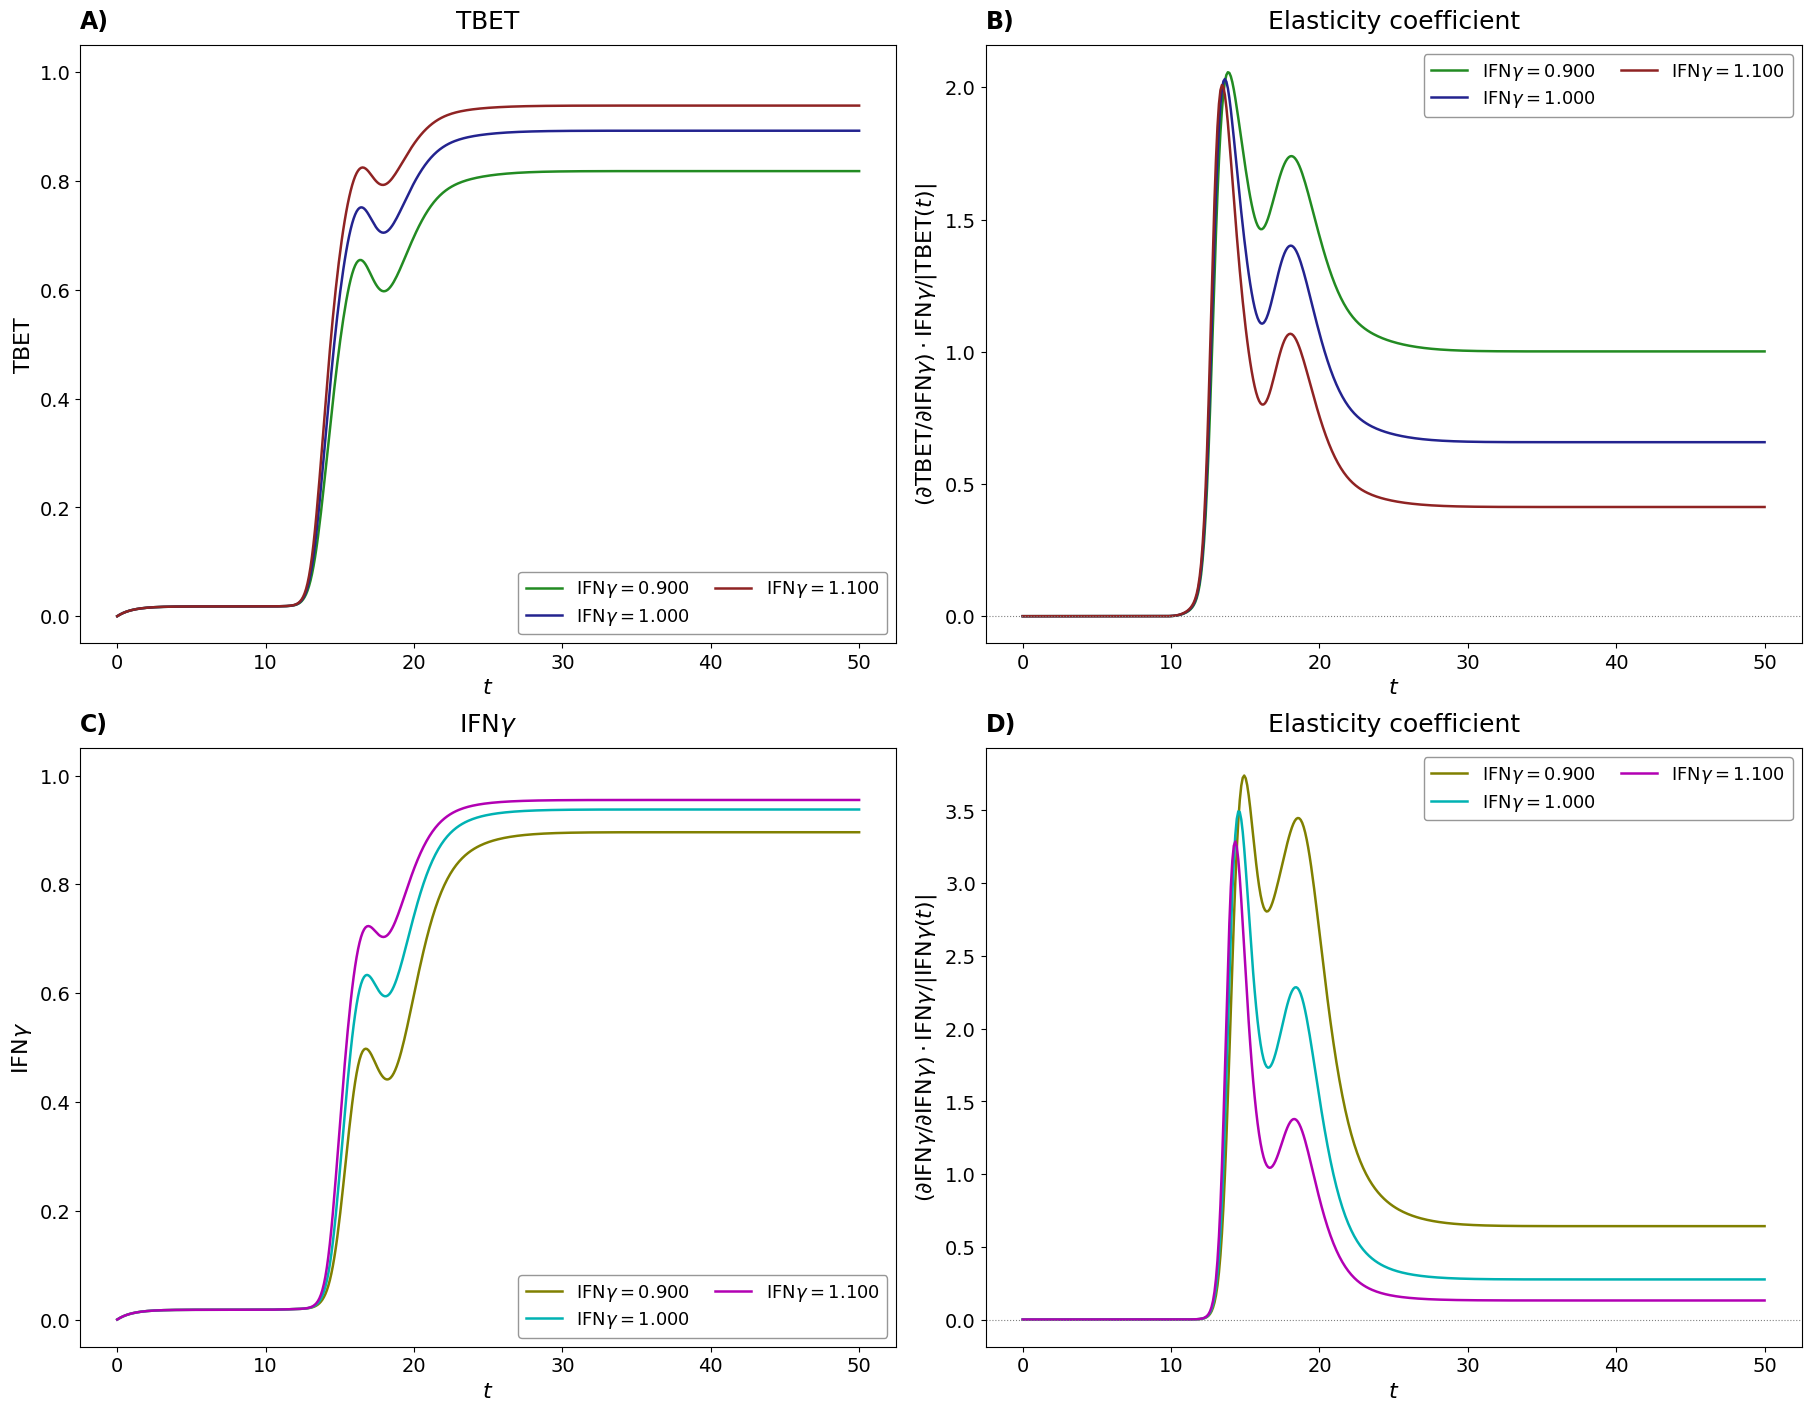

Figura_5.15: env={'LPSE': 1.0, 'IFNGE': 1.0}  pair=('TBET', 'IFNG')  IFNGE in (0.9, 1.1) step 0.1  (3.9 s)  -> ./figures/activities_elasticity_Figura_5.15.png


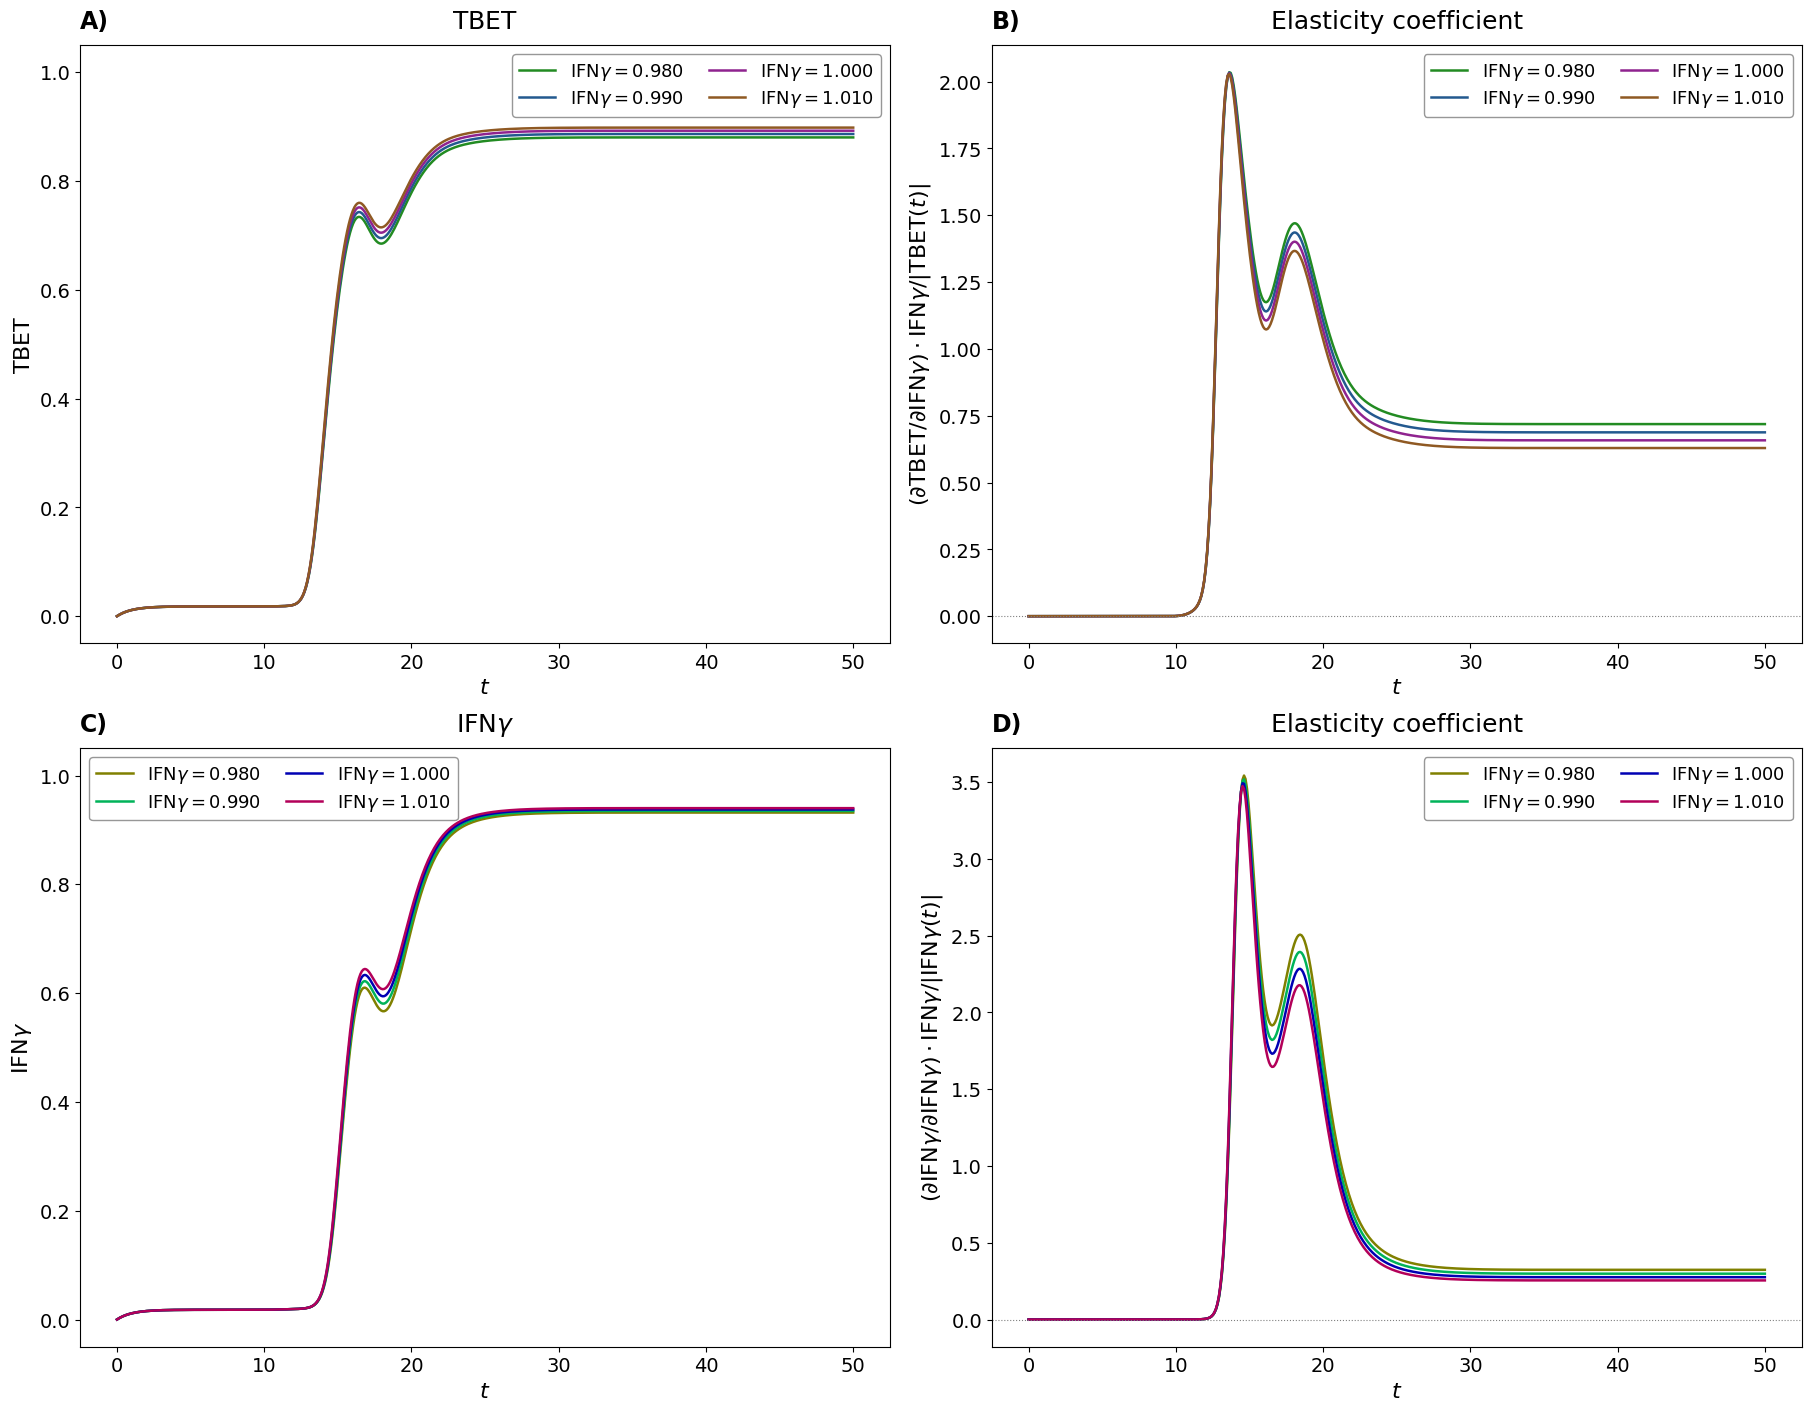

Figura_5.16: env={'LPSE': 1.0, 'IFNGE': 1.0}  pair=('TBET', 'IFNG')  IFNGE in (0.98, 1.01) step 0.01  (4.6 s)  -> ./figures/activities_elasticity_Figura_5.16.png


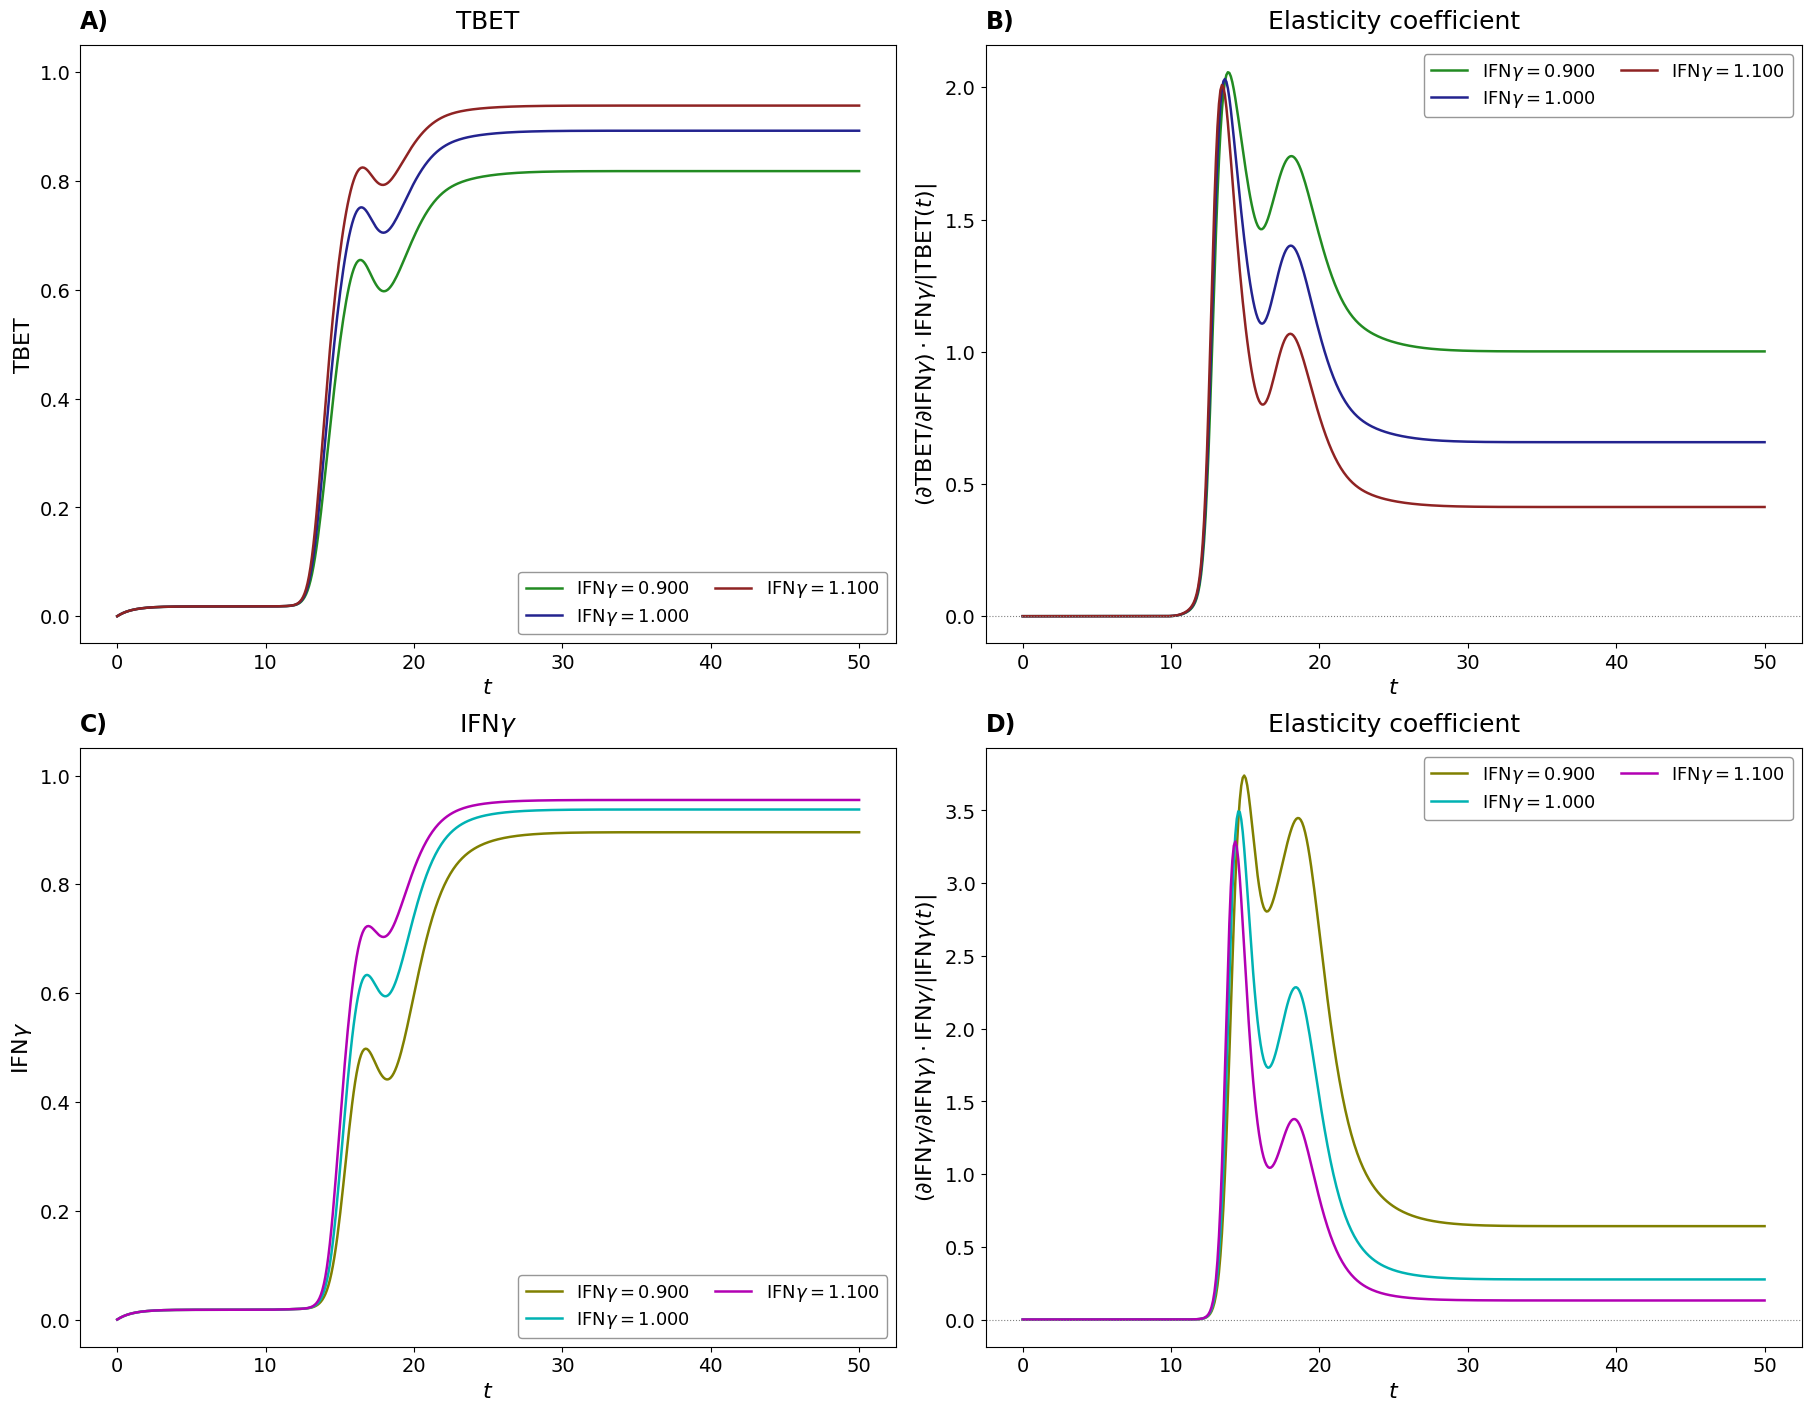

Figura_5.17: env={'LPSE': 1.0, 'SSRNA': 1.0}  pair=('TBET', 'IFNG')  IFNGE in (0.9, 1.1) step 0.1  (3.8 s)  -> ./figures/activities_elasticity_Figura_5.17.png


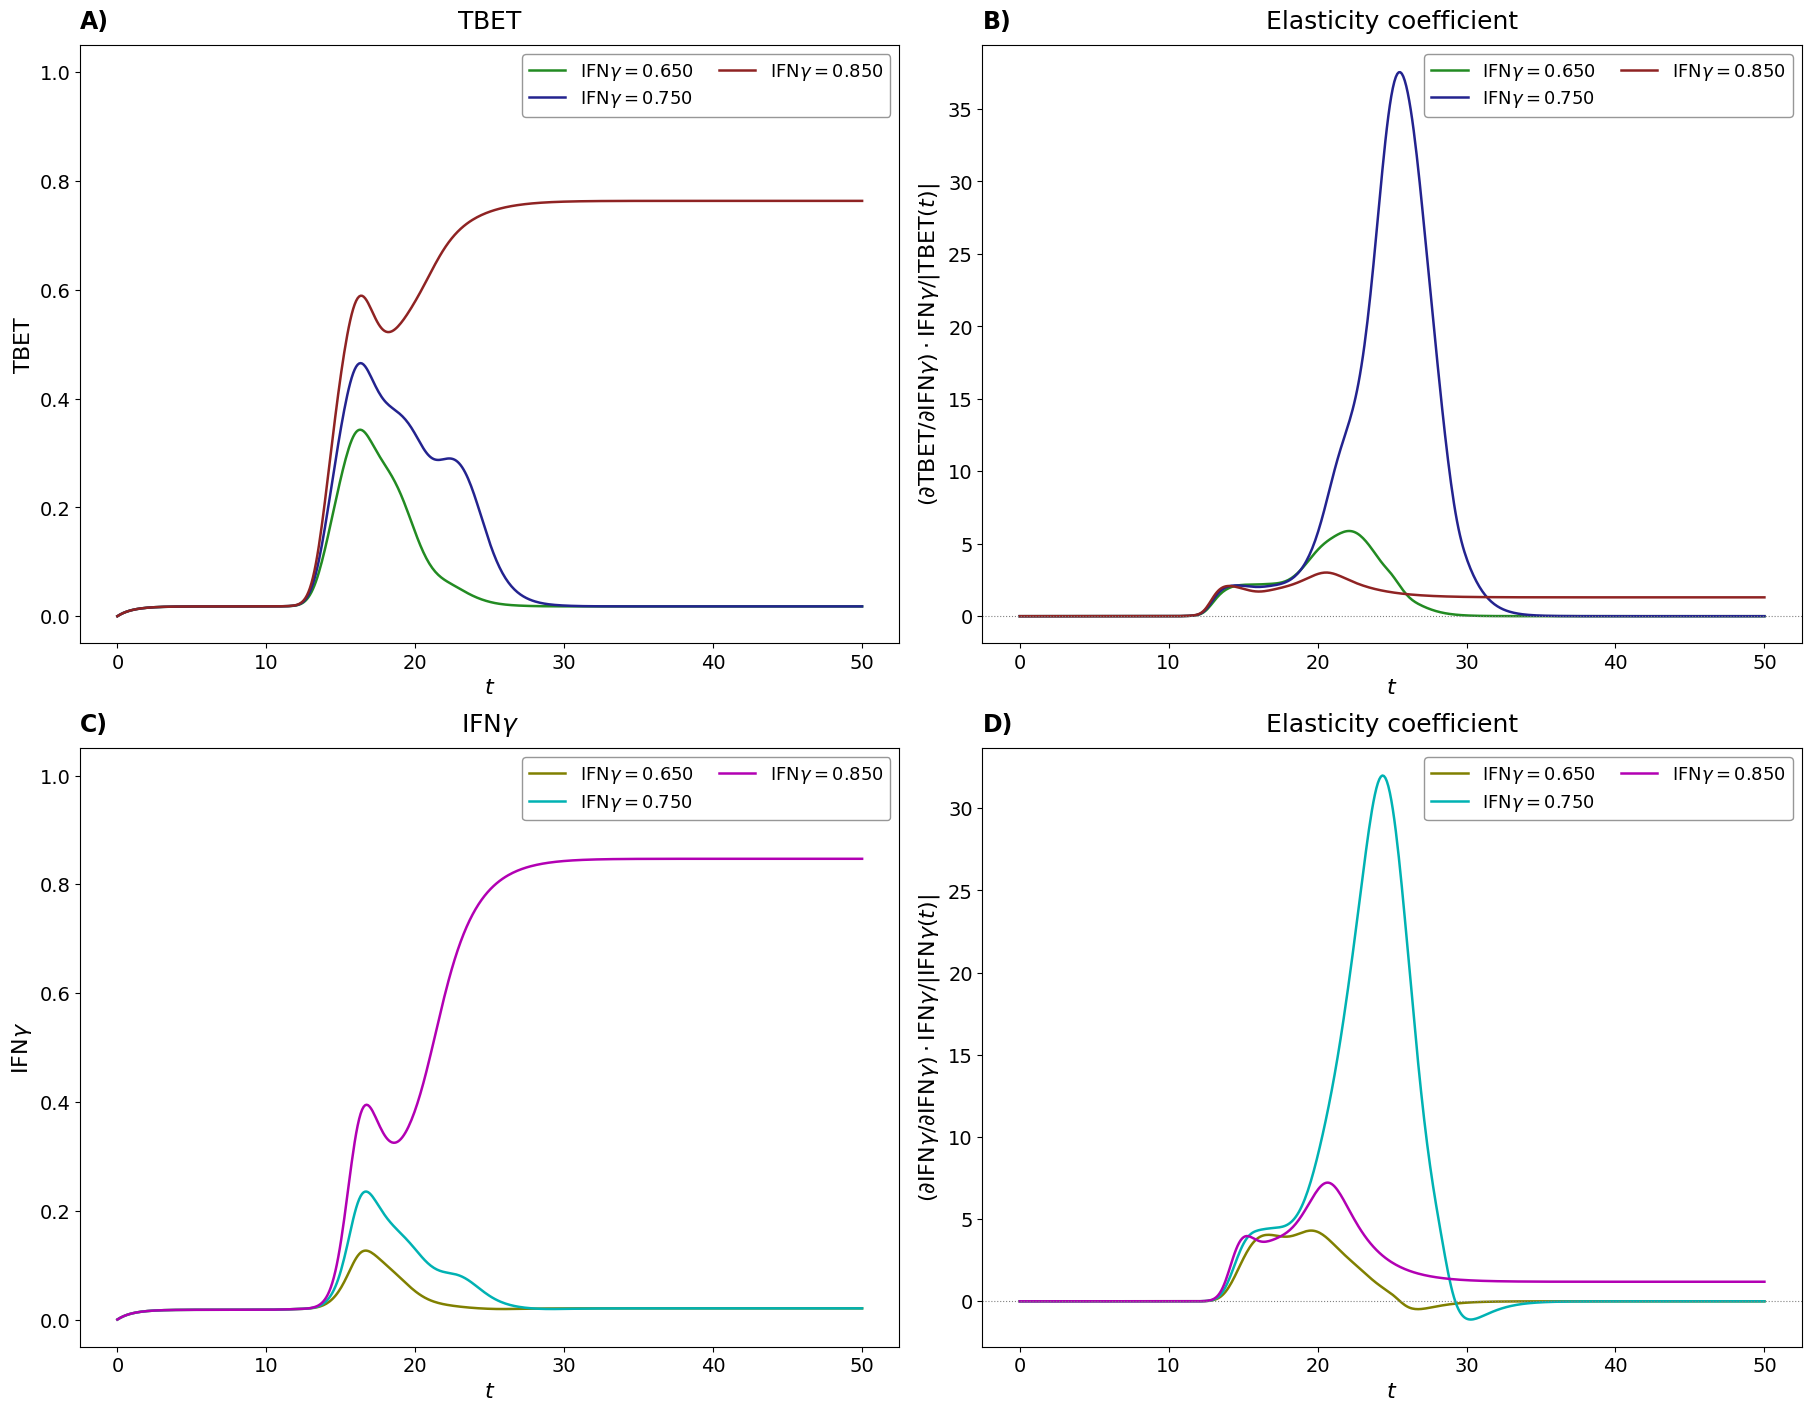

Figura_5.18: env={'LPSE': 1.0, 'SSRNA': 1.0, 'IL4L': 1.0}  pair=('TBET', 'IFNG')  IFNGE in (0.65, 0.85) step 0.1  (4.6 s)  -> ./figures/activities_elasticity_Figura_5.18.png


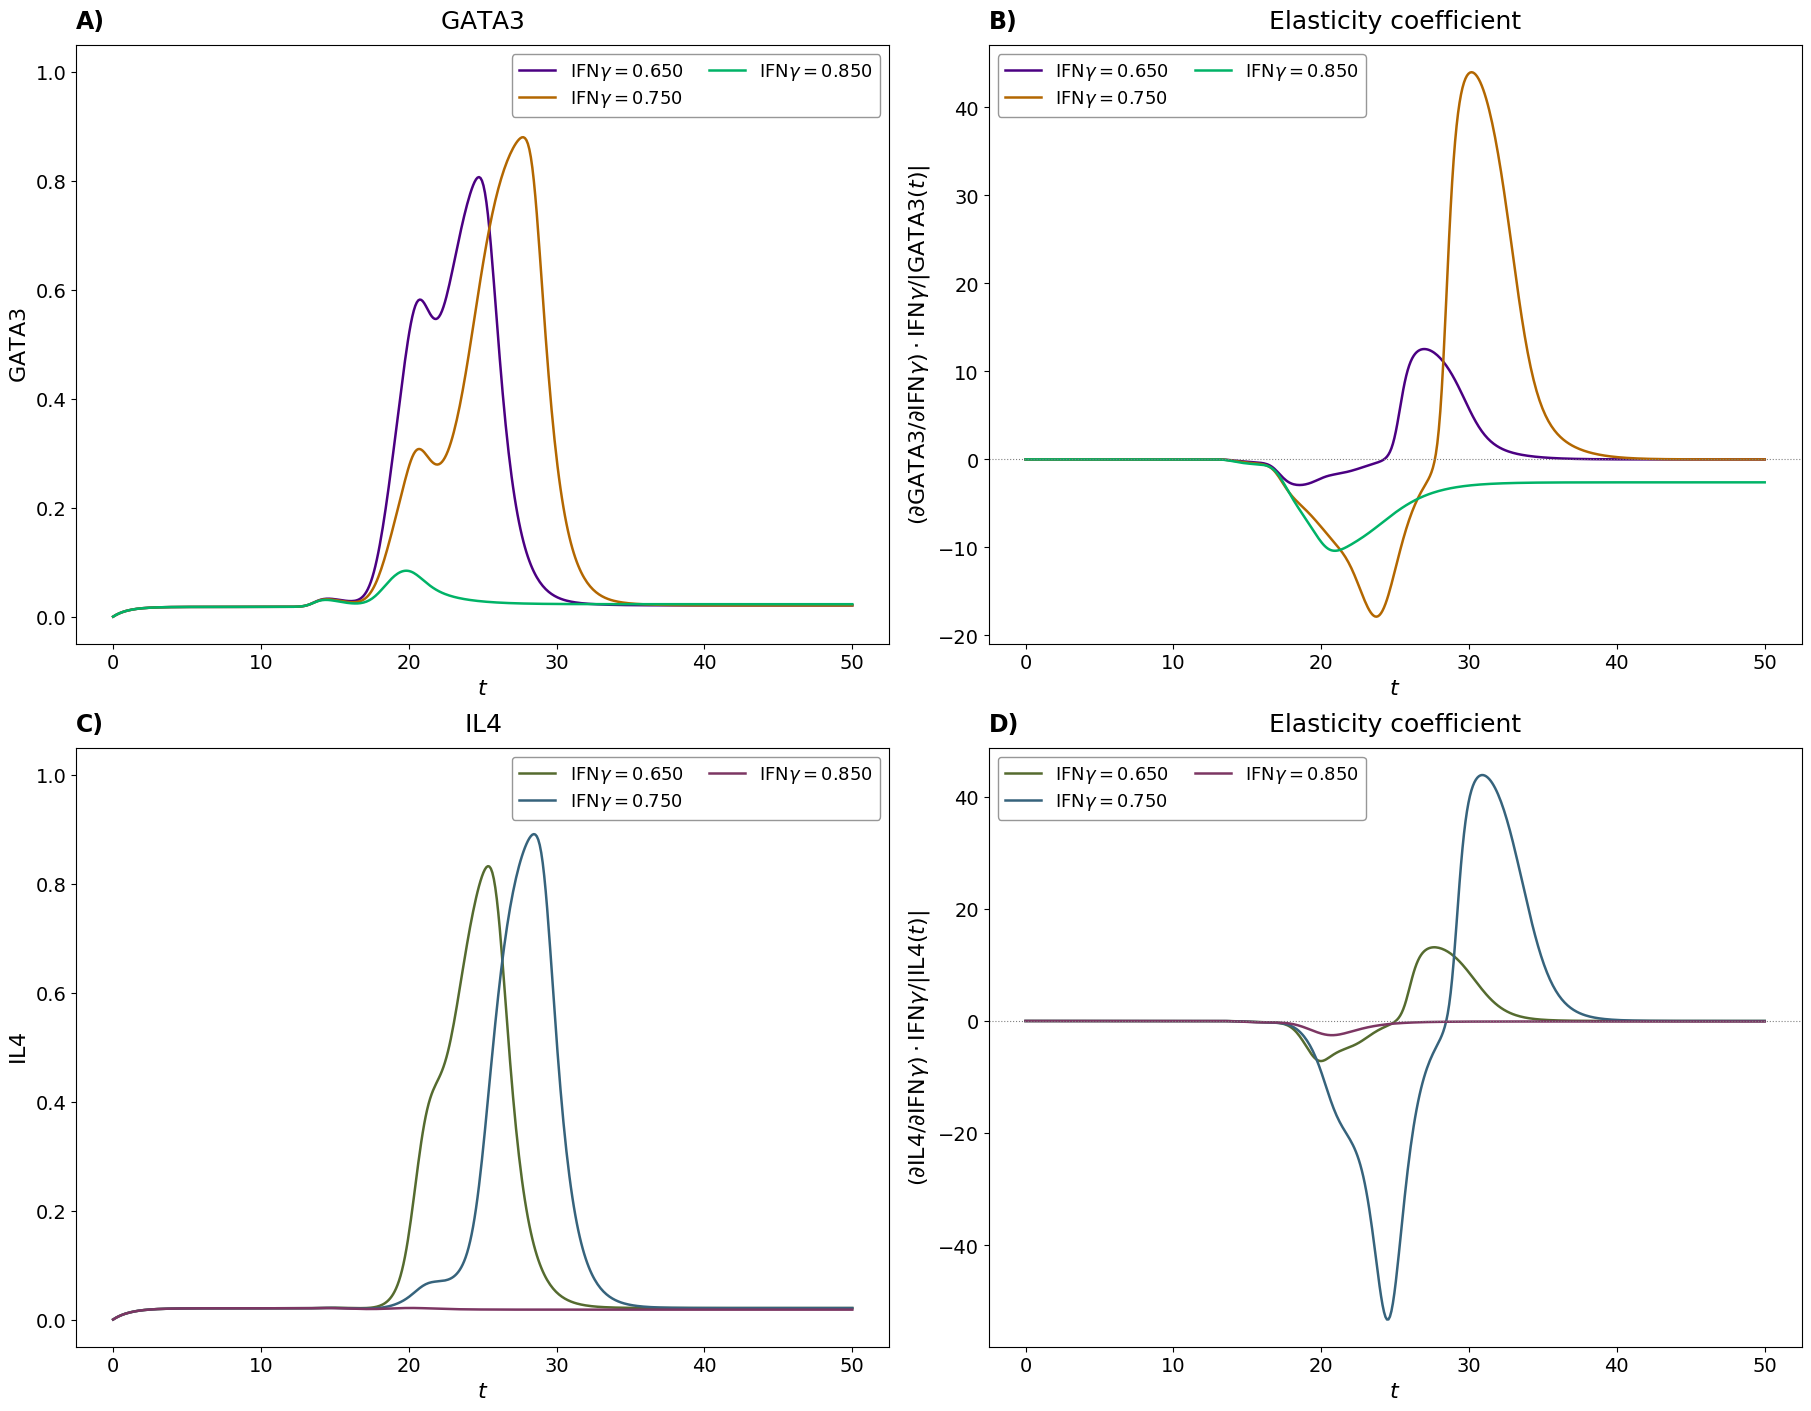

Figura_5.19: env={'LPSE': 1.0, 'SSRNA': 1.0, 'IL4L': 1.0}  pair=('GATA3', 'IL4')  IFNGE in (0.65, 0.85) step 0.1  (4.5 s)  -> ./figures/activities_elasticity_Figura_5.19.png


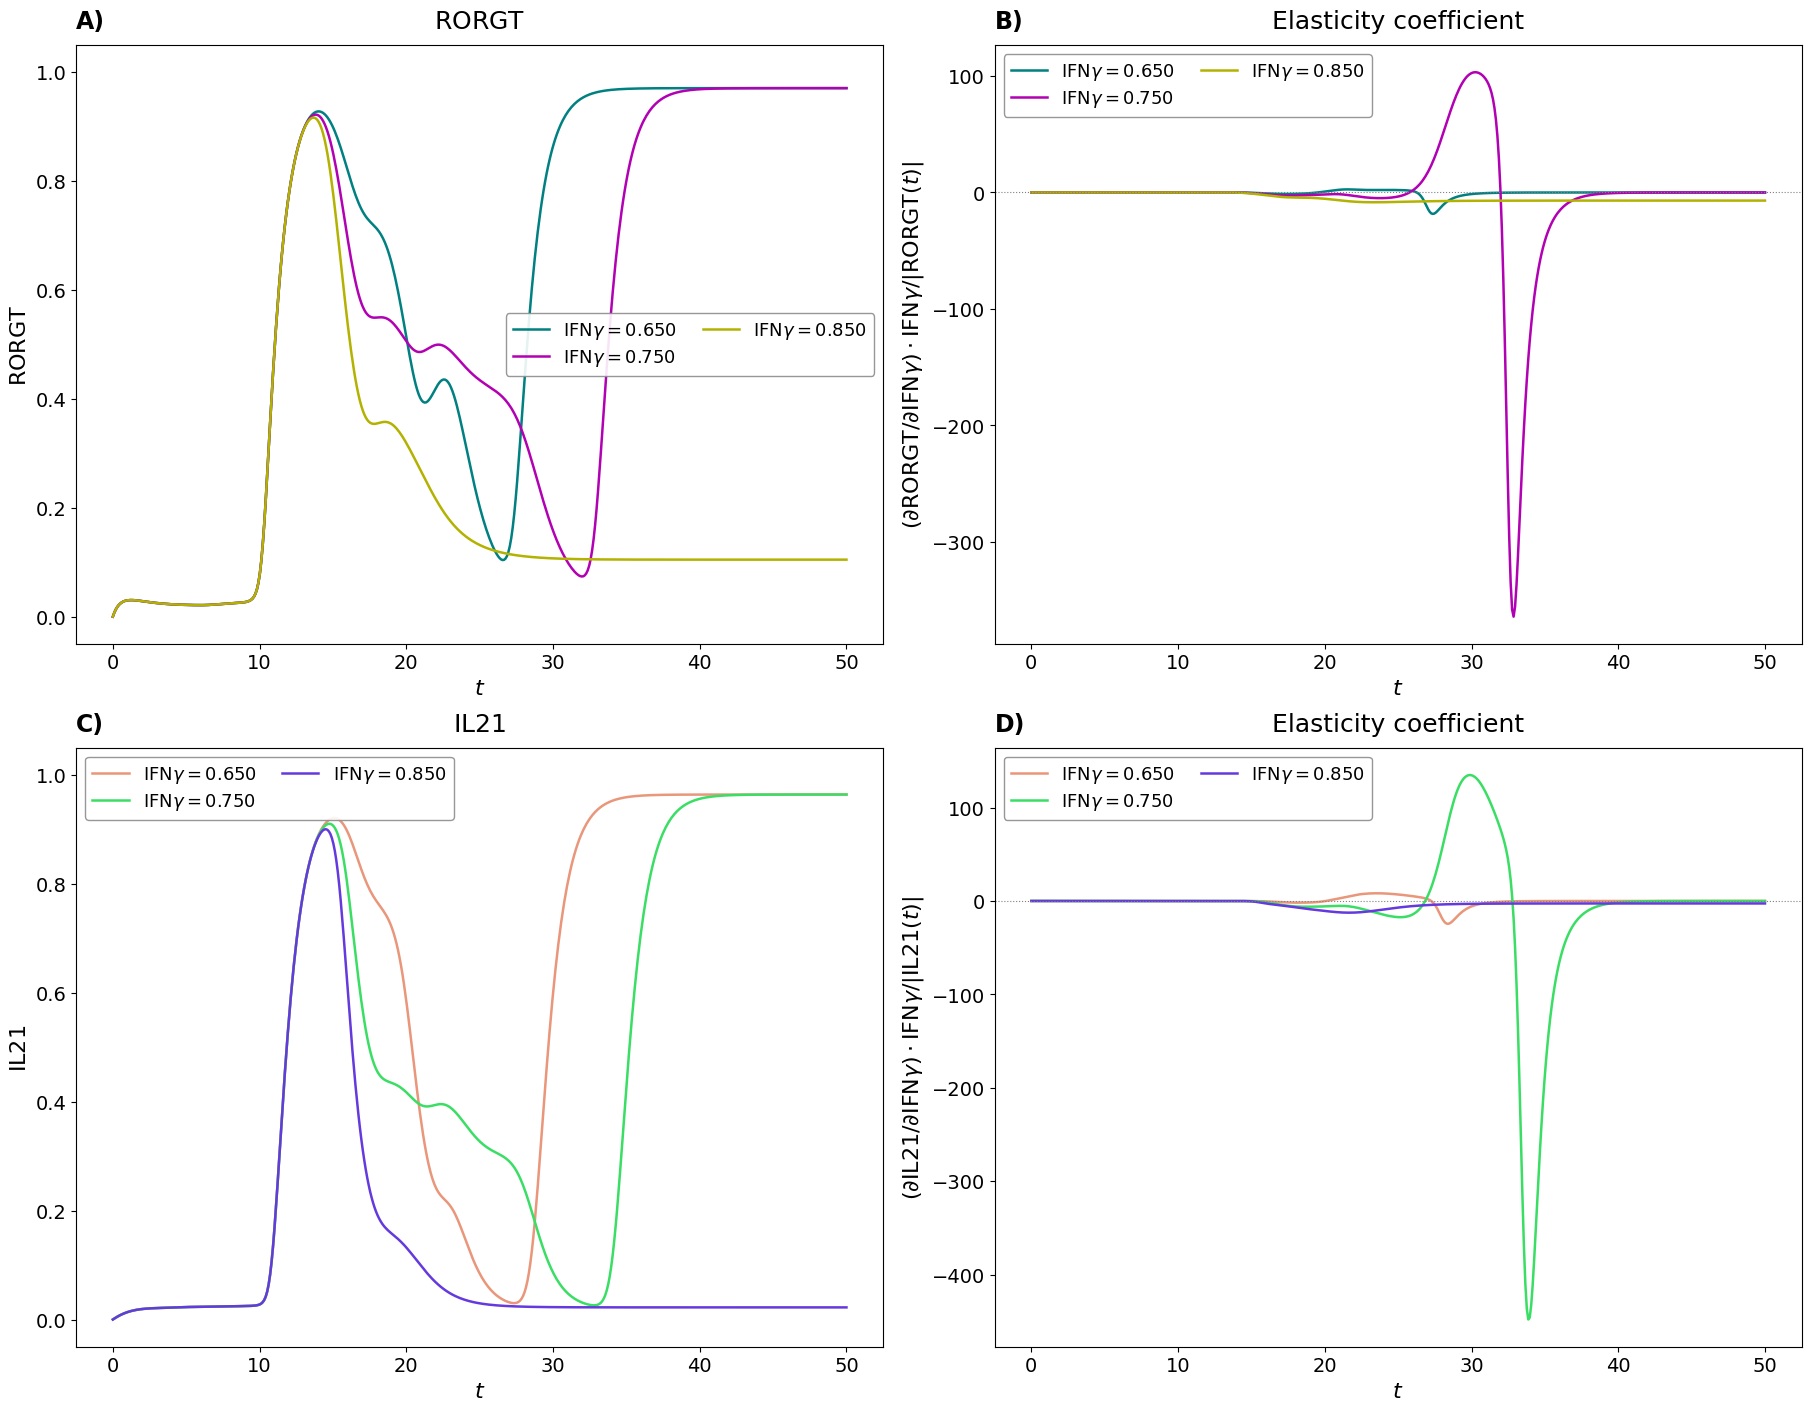

Figura_5.20: env={'LPSE': 1.0, 'SSRNA': 1.0, 'IL4L': 1.0, 'IL21E': 1.0, 'TGFBE': 1.0}  pair=('RORGT', 'IL21')  IFNGE in (0.65, 0.85) step 0.1  (17.0 s)  -> ./figures/activities_elasticity_Figura_5.20.png


In [7]:
import os


def run_case(case, mode=ELASTICITY_MODE, n_show=10):
    p0 = analyzer.case_inputs(case['env_params'])
    values = sweep_values(*case['range'])
    result = analyzer.run(p0, [case['sweep_param']], case['sweep_param'], values, **SOLVER)
    fig = plotter.plot_sensitivity_grid(result, list(case['node_pair']), mode, n_show)
    path = None
    if SAVE_FIGURES:
        os.makedirs(OUTPUT_DIR, exist_ok=True)
        path = os.path.join(OUTPUT_DIR, f"activities_elasticity_{case['label']}.png")
        fig.savefig(path, dpi=300, bbox_inches='tight')
    return result, fig, path


selected = [c for c in CASES if RUN_CASES == 'all' or c['label'] in RUN_CASES]
case_results, report = {}, []
for case in selected:
    t0 = time.time()
    result, fig, path = run_case(case)
    case_results[case['label']] = result
    plt.show()
    print(f"{case['label']}: env={case['env_params']}  pair={case['node_pair']}  "
          f"{case['sweep_param']} in {case['range'][:2]} step {case['range'][2]}  "
          f"({time.time() - t0:.1f} s)" + (f"  -> {path}" if path else ""))
    for row in analyzer.summary(result, list(case['node_pair']), ELASTICITY_MODE):
        report.append({'case': case['label'], **row})

### Report

For every case and node: the range of the activity $q_i$, of the
sensitivity $S_{ij}$ and of the elasticity $\varepsilon_{ij}$ over time and
the sweep, plus $\varepsilon_{ij}(T)$ for the largest swept value. This is
the same report the original notebook printed.

In [8]:
pd.DataFrame(report).round(4)

,case,node,parameter,activity_min,activity_max,sensitivity_min,sensitivity_max,elasticity_min,elasticity_max,elasticity_final
0,Figura_5.15,TBET,IFNGE,0.0,0.9386,0.0000,1.1635,0.0000,2.0572,0.4129
1,Figura_5.15,IFNG,IFNGE,0.0,0.9551,0.0000,1.8205,0.0000,3.7400,0.1309
2,Figura_5.16,TBET,IFNGE,0.0,0.8982,0.0000,1.0298,0.0000,2.0354,0.6292
3,Figura_5.16,IFNG,IFNGE,0.0,0.9400,0.0000,1.4854,0.0000,3.5433,0.2547
4,Figura_5.17,TBET,IFNGE,0.0,0.9386,0.0000,1.1635,0.0000,2.0571,0.4129
5,Figura_5.17,IFNG,IFNGE,0.0,0.9551,0.0000,1.8205,0.0000,3.7400,0.1309
6,Figura_5.18,TBET,IFNGE,0.0,0.7635,0.0000,7.9170,0.0000,37.5396,1.3000
7,Figura_5.18,IFNG,IFNGE,0.0,0.8469,-0.0290,4.1734,-1.1084,31.9873,1.1897
8,Figura_5.19,GATA3,IFNGE,0.0,0.8806,-11.6778,28.4991,-17.8695,44.0010,-2.6044
9,Figura_5.19,IL4,IFNGE,0.0,0.8915,-20.9814,28.6597,-53.2194,43.8465,-0.0872
